In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the healthcare dataset
df = pd.read_csv("../dataset/diabetes_data_upload.csv")

# Display the first 5 rows
df.head()

,Age,Gender,Polyuria,Polydipsia,sudden weight loss,weakness,Polyphagia,Genital thrush,visual blurring,Itching,Irritability,delayed healing,partial paresis,muscle stiffness,Alopecia,Obesity,class
0,40,Male,No,Yes,No,Yes,No,No,No,Yes,No,Yes,No,Yes,Yes,Yes,Positive
1,58,Male,No,No,No,Yes,No,No,Yes,No,No,No,Yes,No,Yes,No,Positive
2,41,Male,Yes,No,No,Yes,Yes,No,No,Yes,No,Yes,No,Yes,Yes,No,Positive
3,45,Male,No,No,Yes,Yes,Yes,Yes,No,Yes,No,Yes,No,No,No,No,Positive
4,60,Male,Yes,Yes,Yes,Yes,Yes,No,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Positive


In [2]:
# Check the basic information about the dataset

print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

Dataset Shape: (520, 17)

Column Names:
['Age', 'Gender', 'Polyuria', 'Polydipsia', 'sudden weight loss', 'weakness', 'Polyphagia', 'Genital thrush', 'visual blurring', 'Itching', 'Irritability', 'delayed healing', 'partial paresis', 'muscle stiffness', 'Alopecia', 'Obesity', 'class']

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 520 entries, 0 to 519
Data columns (total 17 columns):
 #   Column              Non-Null Count  Dtype
---  ------              --------------  -----
 0   Age                 520 non-null    int64
 1   Gender              520 non-null    str  
 2   Polyuria            520 non-null    str  
 3   Polydipsia          520 non-null    str  
 4   sudden weight loss  520 non-null    str  
 5   weakness            520 non-null    str  
 6   Polyphagia          520 non-null    str  
 7   Genital thrush      520 non-null    str  
 8   visual blurring     520 non-null    str  
 9   Itching             520 non-null    str  
 10  Irritability        520 non-n

In [3]:
# Check for missing values
print("Missing Values:")
print(df.isnull().sum())

# Check for duplicate rows
print("\nNumber of Duplicate Rows:")
print(df.duplicated().sum())

Missing Values:
Age                   0
Gender                0
Polyuria              0
Polydipsia            0
sudden weight loss    0
weakness              0
Polyphagia            0
Genital thrush        0
visual blurring       0
Itching               0
Irritability          0
delayed healing       0
partial paresis       0
muscle stiffness      0
Alopecia              0
Obesity               0
class                 0
dtype: int64

Number of Duplicate Rows:
269


In [4]:
# Check unique values in each column

for column in df.columns:
    print("\n", column)
    print(df[column].unique())


 Age
[40 58 41 45 60 55 57 66 67 70 44 38 35 61 54 43 62 39 48 32 42 52 53 37
 49 63 30 50 46 36 51 59 65 25 47 28 68 56 31 85 90 72 69 79 34 16 33 64
 27 29 26]

 Gender
<StringArray>
['Male', 'Female']
Length: 2, dtype: str

 Polyuria
<StringArray>
['No', 'Yes']
Length: 2, dtype: str

 Polydipsia
<StringArray>
['Yes', 'No']
Length: 2, dtype: str

 sudden weight loss
<StringArray>
['No', 'Yes']
Length: 2, dtype: str

 weakness
<StringArray>
['Yes', 'No']
Length: 2, dtype: str

 Polyphagia
<StringArray>
['No', 'Yes']
Length: 2, dtype: str

 Genital thrush
<StringArray>
['No', 'Yes']
Length: 2, dtype: str

 visual blurring
<StringArray>
['No', 'Yes']
Length: 2, dtype: str

 Itching
<StringArray>
['Yes', 'No']
Length: 2, dtype: str

 Irritability
<StringArray>
['No', 'Yes']
Length: 2, dtype: str

 delayed healing
<StringArray>
['Yes', 'No']
Length: 2, dtype: str

 partial paresis
<StringArray>
['No', 'Yes']
Length: 2, dtype: str

 muscle stiffness
<StringArray>
['Yes', 'No']
Length: 2, 

In [5]:
# Clean column names

df.columns = (
    df.columns
    .str.strip()
    .str.lower()
    .str.replace(" ", "_")
)

# Display the cleaned column names
print(df.columns.tolist())

['age', 'gender', 'polyuria', 'polydipsia', 'sudden_weight_loss', 'weakness', 'polyphagia', 'genital_thrush', 'visual_blurring', 'itching', 'irritability', 'delayed_healing', 'partial_paresis', 'muscle_stiffness', 'alopecia', 'obesity', 'class']


In [6]:
# Convert categorical values into numbers

# Yes = 1, No = 0
yes_no_columns = [
    'polyuria',
    'polydipsia',
    'sudden_weight_loss',
    'weakness',
    'polyphagia',
    'genital_thrush',
    'visual_blurring',
    'itching',
    'irritability',
    'delayed_healing',
    'partial_paresis',
    'muscle_stiffness',
    'alopecia',
    'obesity'
]

for column in yes_no_columns:
    df[column] = df[column].map({'Yes': 1, 'No': 0})

# Gender: Male = 1, Female = 0
df['gender'] = df['gender'].map({'Male': 1, 'Female': 0})

# Class: Positive = 1, Negative = 0
df['class'] = df['class'].map({'Positive': 1, 'Negative': 0})

# Display the first 5 rows
df.head()

,age,gender,polyuria,polydipsia,sudden_weight_loss,weakness,polyphagia,genital_thrush,visual_blurring,itching,irritability,delayed_healing,partial_paresis,muscle_stiffness,alopecia,obesity,class
0,40,1,0,1,0,1,0,0,0,1,0,1,0,1,1,1,1
1,58,1,0,0,0,1,0,0,1,0,0,0,1,0,1,0,1
2,41,1,1,0,0,1,1,0,0,1,0,1,0,1,1,0,1
3,45,1,0,0,1,1,1,1,0,1,0,1,0,0,0,0,1
4,60,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1


In [7]:
# Check for missing values after encoding

print("Missing values in each column:")
print(df.isnull().sum())

print("\nData types:")
print(df.dtypes)

Missing values in each column:
age                   0
gender                0
polyuria              0
polydipsia            0
sudden_weight_loss    0
weakness              0
polyphagia            0
genital_thrush        0
visual_blurring       0
itching               0
irritability          0
delayed_healing       0
partial_paresis       0
muscle_stiffness      0
alopecia              0
obesity               0
class                 0
dtype: int64

Data types:
age                   int64
gender                int64
polyuria              int64
polydipsia            int64
sudden_weight_loss    int64
weakness              int64
polyphagia            int64
genital_thrush        int64
visual_blurring       int64
itching               int64
irritability          int64
delayed_healing       int64
partial_paresis       int64
muscle_stiffness      int64
alopecia              int64
obesity               int64
class                 int64
dtype: object


In [8]:
# Check and remove duplicate rows

before = df.shape[0]

df = df.drop_duplicates()

after = df.shape[0]

print("Rows before removing duplicates:", before)
print("Rows after removing duplicates:", after)
print("Duplicates removed:", before - after)

Rows before removing duplicates: 520
Rows after removing duplicates: 251
Duplicates removed: 269


In [9]:
# Save the cleaned dataset

output_path = "../dataset/cleaned_diabetes_data.csv"

df.to_csv(output_path, index=False)

print("Cleaned dataset saved successfully!")
print("File location:", output_path)

Cleaned dataset saved successfully!
File location: ../dataset/cleaned_diabetes_data.csv


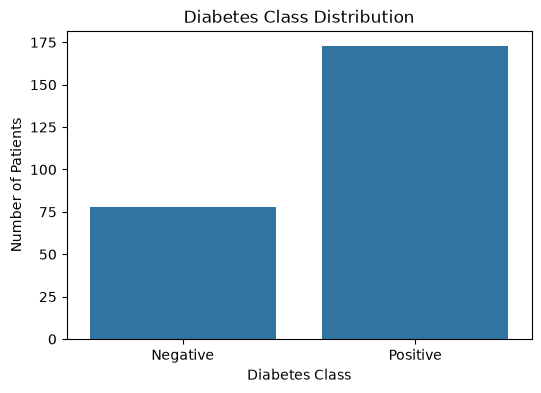

In [10]:
# Diabetes class distribution

plt.figure(figsize=(6, 4))

sns.countplot(x='class', data=df)

plt.title('Diabetes Class Distribution')
plt.xlabel('Diabetes Class')
plt.ylabel('Number of Patients')

plt.xticks([0, 1], ['Negative', 'Positive'])

plt.show()